# **`1.Chargement du dataset`**

In [2]:
# Import des bibliothèques nécessaires pour cette étape
import pandas as pd
import numpy as np

# Chargement du fichier
data = pd.read_csv("AirPassengers.csv")
data.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


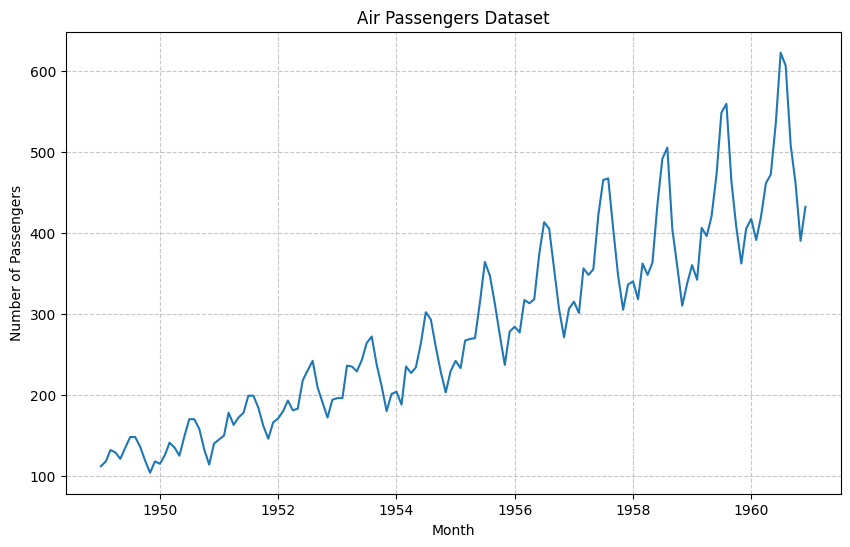

In [62]:
# 2. Préparation des données
# On s'assure que la colonne Month est au format datetime
data['Month'] = pd.to_datetime(data['Month'])

# 3. Création du graphique
plt.figure(figsize=(10, 6))
plt.plot(data['Month'], data['Passengers'], label='Number of Passengers')

# 4. Personnalisation pour ressembler à votre image
plt.title('Air Passengers Dataset')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [56]:
# Conversion en type float
data = data.rename(columns={"#Passengers": "Passengers"})
data['Passengers'] = data['Passengers'].astype(float)

# Extraction des valeurs et mise en forme
values = data['Passengers'].values.reshape(-1, 1)

print(data.head())

       Month  Passengers
0 1949-01-01       112.0
1 1949-02-01       118.0
2 1949-03-01       132.0
3 1949-04-01       129.0
4 1949-05-01       121.0


Explication

On charge le dataset avec pandas.

On convertit la colonne "Passengers" en float car les réseaux de neurones utilisent des valeurs numériques.

On transforme les données en format matriciel compatible avec sklearn et Keras.

# **`2.Normalisation des données`**

In [57]:
# Import du scaler
from sklearn.preprocessing import MinMaxScaler

# Normalisation entre 0 et 1
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data = scaler.fit_transform(values)

Explication

Les réseaux de neurones fonctionnent mieux avec des données normalisées.

MinMaxScaler transforme les valeurs entre 0 et 1.

Cela rend l’entraînement plus stable et plus rapide.

# **`3.Création des séquences (adaptation au RNN)`**

In [30]:
# Fonction pour créer les séquences
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])
    return np.array(X), np.array(y)

# On utilise 12 mois (saisonnalité annuelle)
window_size = 12

X, y = create_sequences(scaled_data, window_size)

print("Dimension de X :", X.shape)
print("Dimension de y :", y.shape)

Dimension de X : (132, 12, 1)
Dimension de y : (132, 1)


Explication

Un RNN travaille sur des séquences, pas sur des valeurs isolées.

On utilise une fenêtre de 12 mois pour capturer la saisonnalité annuelle.

Les 12 mois servent d’entrée pour prédire le mois suivant.

# **`4.Séparation Train / Test (respect de l’ordre temporel)`**

In [31]:
# Séparation 80% entraînement / 20% test
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]
y_train = y[:train_size]
y_test = y[train_size:]

Explication

On ne mélange pas les données.

En séries temporelles, l’ordre est très important.

Le modèle apprend sur le passé et prédit le futur.

# **`5.Construction du modèle RNN`**

In [44]:
# Import des couches nécessaires
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

# Création du modèle
model = Sequential()

# Couche RNN
model.add(SimpleRNN(50, activation='tanh', input_shape=(window_size, 1)))

# Dropout
model.add(Dropout(0.2))

# Couche de sortie
model.add(Dense(1))

# Compilation
model.compile(optimizer='adam', loss='mse')

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_5 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Explication

SimpleRNN avec 50 neurones pour apprendre les dépendances temporelles.

Fonction d’activation tanh (classique pour RNN).

Une couche Dense(1) pour prédire une seule valeur.

Optimiseur Adam (performant et adaptatif).

Fonction de perte MSE car c’est un problème de régression.


# **`6.Entraînement du modèle`**

In [45]:
#importation et definition du early stop
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
    monitor='val_loss',   # surveille la loss de validation
    patience=10,          # attend 10 epochs sans amélioration
    restore_best_weights=True  # garde les meilleurs poids
)
# Entraînement
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.1741 - val_loss: 0.0202
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0114 - val_loss: 0.0406
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0041 - val_loss: 0.0117
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0082 - val_loss: 0.0185
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0056 - val_loss: 0.0120
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0061 - val_loss: 0.0120
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0042 - val_loss: 0.0103
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0042 - val_loss: 0.0109
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0034 - val_loss: 0.0119
Epoch 10/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0035 - val_loss: 0.0106
Epoch 11/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0031 - val_loss: 0.0115
Epoch 12/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

Explication

100 epochs pour permettre au modèle d’apprendre.

Batch size = 8 car dataset petit.

On observe la validation loss pour détecter le surapprentissage.

# **`7.Prédictions et évaluation`**

In [58]:
# Import métrique
from sklearn.metrics import mean_squared_error
import numpy as np

# Prédictions
predictions = model.predict(X_test)

# Retour à l’échelle originale
predictions = scaler.inverse_transform(predictions)
y_test_real = scaler.inverse_transform(y_test)

# Calcul du RMSE
mse = mean_squared_error(y_test_real, predictions)
rmse = np.sqrt(mse)

print("RMSE :", rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
RMSE : 23.478379961502657


Explication

On reconvertit les données à l’échelle originale.

On calcule le RMSE.

Plus le RMSE est faible, plus le modèle est précis.

# **`8.Comparaison valeurs réelles vs prédictions`**

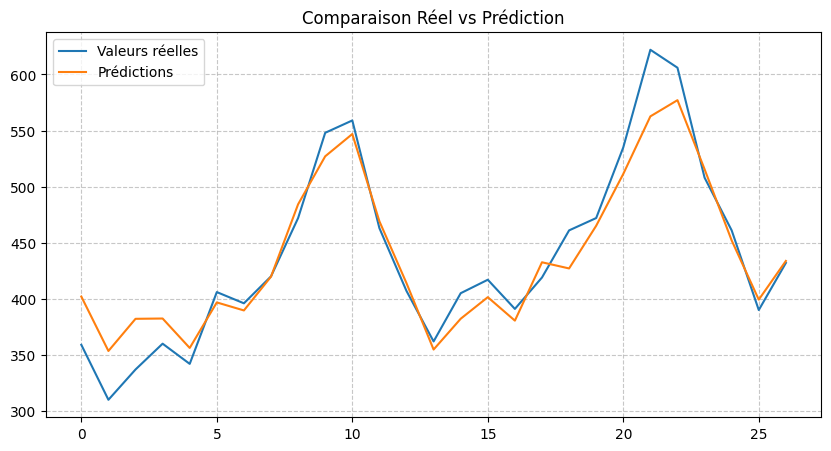

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(y_test_real, label="Valeurs réelles")
plt.plot(predictions, label="Prédictions")
plt.legend()
plt.title("Comparaison Réel vs Prédiction")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

On compare visuellement les résultats.

Si les deux courbes sont proches → bon modèle.

# **`9.Courbes d’apprentissage`**

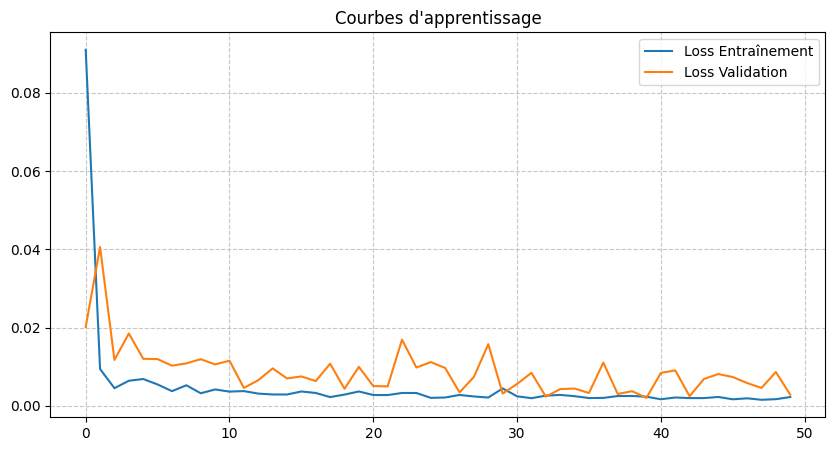

In [54]:
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Loss Entraînement')
plt.plot(history.history['val_loss'], label='Loss Validation')
plt.legend()
plt.title("Courbes d'apprentissage")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Explication

Si train et validation diminuent ensemble → bon apprentissage.

Si validation augmente pendant que train diminue → surapprentissage.